# How nested evaluation controls selection bias

This native Julia companion preserves the public observations, weighted linear/RBF C-SVC objective, unweighted training standardization, gamma scale rule, 0.001 solver tolerance, protected folds and parameter grids. Native fitting reproduces the public class ordering, Float32 kernel cache and shrinking procedure. Saved public seed-16 candidate and bootstrap draws supply randomness without supplying fitted outputs. Manual surfaces use unweighted F1; the released search retains its supplier contract routing top-level weights to fitting and scoring. Observation positions are one-based, and outputs are saved under `outputs/julia`.

The inner validation score for a candidate setting is the average of its held-out fold scores:

$$
\overline s_m(\theta)=\frac{1}{K_{\mathrm{in}}}\sum_{j=1}^{K_{\mathrm{in}}} s_{m,j}(\theta).
$$

Here, $m$ identifies an outer split, $\theta$ is a candidate setting, $K_{\mathrm{in}}$ is the number of inner folds, $s_{m,j}(\theta)$ is the held-out score on inner fold $j$, and $\overline s_m(\theta)$ is the mean inner score.

In [1]:
include(joinpath("..","support","BookFeatureMath.jl"))
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("18_hyperparameter_selection");
using CSV, TOML, Printf
include(joinpath("..","support","BookEstimators.jl"))
include(joinpath("..","support","BookSVC.jl"))
using RiskLabAI.Validation: KFoldCV,PurgedKFoldCV,cv_split,filtered_training_indices_with_embargo,SampleWeightedPipeline,clf_hyper_fit,predict_pipeline,predict_pipeline_proba
prefix = "nested"
raw = load_binance()
raw.interval = floor.(raw.time,Minute(15))

function compensated_sum(values)
    total,correction = 0.,0.
    for value in values
        adjusted = value-correction
        updated = total+adjusted
        correction = updated-total-adjusted
        total = updated
    end
    return total
end

bars = combine(groupby(raw,:interval;sort=true),:close=>last=>:Close,:volume=>compensated_sum=>:Volume,:quote_volume=>compensated_sum=>Symbol("Quote volume"),:trades=>compensated_sum=>:Trades)
function rolling_standard_deviation(values,window)
    result = fill(NaN,length(values))
    count,center,squares,add_correction,remove_correction = 0,0.,0.,0.,0.
    for index in eachindex(values)
        if index>window && isfinite(values[index-window])
            value = values[index-window]
            count -= 1
            if count>0
                previous = center-remove_correction
                adjusted = value-remove_correction
                difference = adjusted-center
                remove_correction = difference+center-adjusted
                center -= difference/count
                squares -= (value-previous)*(value-center)
            else
                center,squares = 0.,0.
            end
        end
        value = values[index]
        if isfinite(value)
            count += 1
            previous = center-add_correction
            adjusted = value-add_correction
            difference = adjusted-center
            add_correction = difference+center-adjusted
            center += difference/count
            squares += (value-previous)*(value-center)
        end
        count==window && (result[index]=sqrt(max(0.,squares/(count-1))))
    end
    return result
end

function exponential_average(values,span)
    alpha = 2/(span+1)
    result = copy(values)
    for index in 2:length(values)
        result[index] = (1-alpha)*result[index-1]+alpha*values[index]
    end
    return result
end

levels = BookFeatureMath.runtime_log.(bars.Close)
returns = vcat(NaN,diff(levels))
positions = collect(18:nrow(bars)-8)
feature_names = ["Previous return","Distance from EWM 15","Distance from EWM 55","One-hour return","Past volatility","Log volume change"]
public_x = hcat(returns[positions.-1],(levels.-BookFeatureMath.runtime_log.(exponential_average(bars.Close,15)))[positions.-1],(levels.-BookFeatureMath.runtime_log.(exponential_average(bars.Close,55)))[positions.-1],levels[positions.-1].-levels[positions.-5],rolling_standard_deviation(returns,16)[positions.-1],diff(BookFeatureMath.runtime_log1p.(bars.Volume))[positions.-2])
dates,event_times = bars.interval[positions],bars.interval[positions.+8]
forward_returns = levels[positions.+8].-levels[positions]
public_y = Int.(forward_returns.>0)
sample_weight = clamp.(abs.(forward_returns)./median(abs.(forward_returns)),.25,4.)
count_observations = length(public_y)
feature_frame = DataFrame(position=collect(1:count_observations),bar_position=positions,date=dates,end_time=event_times,forward_return=forward_returns,target=public_y,weight=sample_weight)
for (column,name) in enumerate(feature_names)
    feature_frame[!,name] = public_x[:,column]
end
save_data(feature_frame,paths,prefix*"_features")
save_data(bars,paths,prefix*"_bars")
@assert nrow(bars)==2976 && size(public_x)==(2951,6)
@assert all(isfinite,public_x) && all(value->.25<=value<=4.,sample_weight)
violet = "#C084FC"
format_time(value) = Dates.format(value,dateformat"yyyy-mm-dd HH:MM:SS")
configuration_name(kernel,penalty) = uppercase(string(kernel))*", C="*@sprintf("%g",penalty)
configurations(penalties) = [(kernel,Float64(penalty)) for kernel in ["linear","rbf"] for penalty in penalties]
selected_row(frame) = first(eachrow(sort(frame,["Mean F1","Order"];rev=[true,false])))
table(frame,name,caption) = save_table(frame,paths,name;caption,label="tab:chapter18-"*replace(name,"_"=>"-"))
fit_cache = Dict{Tuple,Any}()
fit_records,prediction_records = NamedTuple[],NamedTuple[]

function f1_value(actual,predicted;weights=ones(length(actual)))
    true_positive = sum(weights[(actual.==1).&(predicted.==1)])
    false_positive = sum(weights[(actual.==0).&(predicted.==1)])
    false_negative = sum(weights[(actual.==1).&(predicted.==0)])
    denominator = 2true_positive+false_positive+false_negative
    return denominator==0 ? 0. : 2true_positive/denominator
end

function record_fit(model,kernel,penalty,train,weights;source="manual")
    number = length(fit_records)+1
    push!(fit_records,(fit=number,source=source,kernel=string(kernel),C=Float64(penalty),observations=length(train),weight_sum=sum(weights),support_vectors=count(>(0),model.alpha),intercept=model.intercept,gamma=model.gamma,iterations=model.iterations,converged=model.converged,kkt_violation=model.kkt_violation,dual_objective=model.dual_objective,primal_objective=model.primal_objective))
    save_data(DataFrame(position=train,weight=weights),paths,prefix*"_fit_"*string(number)*"_weights")
    save_data(DataFrame(fit_records),paths,prefix*"_fits")
    @assert model.converged
    return number
end

function fitted_for(kernel,penalty,train;weights=sample_weight[train])
    key = (string(kernel),Float64(penalty),Tuple(train),Tuple(weights))
    return get!(fit_cache,key) do
        model = BookSVC.fit_svc(public_x[train,:],public_y[train];sample_weight=weights,C=penalty,kernel=Symbol(kernel))
        number = record_fit(model,kernel,penalty,train,weights)
        return model,number
    end
end

function record_predictions(model,number,test,key)
    scores = BookEstimators.decision_function(model,public_x[test,:])
    predictions = BookEstimators.predict(model,public_x[test,:])
    for (position,prediction,score) in zip(test,predictions,scores)
        push!(prediction_records,(case=key,fit=number,position=position,prediction=prediction,score=score))
    end
    return predictions
end

function evaluate(kernel,penalty,train,test,key)
    model,number = fitted_for(kernel,penalty,train)
    return f1_value(public_y[test],record_predictions(model,number,test,key))
end

function save_predictions()
    isempty(prediction_records) || save_data(DataFrame(prediction_records),paths,prefix*"_predictions")
    return nothing
end

function configuration_surface(configs;rows=collect(1:count_observations),folds=5,embargo=.01,ordinary=false,key)
    local_splits = ordinary ? cv_split(KFoldCV(folds),length(rows)) : cv_split(PurgedKFoldCV(folds,dates[rows],event_times[rows];embargo))
    splits = [(rows[train],rows[test]) for (train,test) in local_splits]
    memberships = DataFrame(fold=Int[],role=String[],order=Int[],position=Int[])
    for (fold,(train,test)) in enumerate(splits), (role,indices) in [("train",train),("test",test)]
        append!(memberships,DataFrame(fold=fill(fold,length(indices)),role=fill(role,length(indices)),order=collect(eachindex(indices)),position=indices))
    end
    save_data(memberships,paths,key*"_splits")
    records = NamedTuple[]
    for (order,(kernel,penalty)) in enumerate(configs)
        scores = [evaluate(kernel,penalty,train,test,key*"_"*string(order)*"_"*string(fold)) for (fold,(train,test)) in enumerate(splits)]
        push!(records,(order=order-1,configuration=configuration_name(kernel,penalty),kernel=kernel,penalty=penalty,mean=mean(scores),spread=std(scores),minimum=minimum(scores),maximum=maximum(scores),training=mean(length(train) for (train,_) in splits),removed=mean(length(rows)-length(train)-length(test) for (train,test) in splits)))
    end
    result = DataFrame(records)
    rename!(result,["Order","Configuration","Kernel","C","Mean F1","F1 spread","Smallest fold F1","Largest fold F1","Mean training observations","Mean removed observations"])
    ordinary && (result=select(result,1:8))
    save_data(result,paths,key*"_surface")
    save_predictions()
    return result,splits
end

function overlap_count(train,test)
    allowed = Set(filtered_training_indices_with_embargo(dates,event_times,test;embargo=0.,continuous=true))
    return count(index->index∉allowed,train)
end

function selection_frequency(frame,count_name)
    result = combine(groupby(frame,["Selected kernel","Selected C"];sort=true),nrow=>count_name)
    result[!,"Selection share"] = result[!,count_name]./nrow(frame)
    return result
end

function read_primitive(name)
    root = joinpath("..","data","chapter18_random_inputs")
    manifest_path = joinpath(root,"inputs.toml")
    entry = TOML.parsefile(manifest_path)["files"][name]
    path = joinpath(root,name)
    return CSV.read(path,DataFrame)
end

function native_pipeline(source)
    row_lookup = Dict(Tuple(row)=>index for (index,row) in enumerate(eachrow(public_x)))
    current_train,current_scaler = Ref(Int[]),Ref(BookSVC.fit_scaler(public_x))
    fit_step = function(name,step,data,labels,options)
        if name=="scale"
            current_train[] = [row_lookup[Tuple(row)] for row in eachrow(data)]
            current_scaler[] = BookSVC.fit_scaler(data)
            return current_scaler[]
        end
        weights = get(options,"sample_weight",ones(length(labels)))
        model = BookSVC.fit_svc(data,labels;sample_weight=weights,C=step.C,kernel=Symbol(step.kernel),standardize=false)
        number = record_fit(model,step.kernel,step.C,current_train[],weights;source)
        transformed = BookEstimators.transform(current_scaler[],public_x)
        lookup = Dict(Tuple(row)=>index for (index,row) in enumerate(eachrow(transformed)))
        return (;model,number,lookup,kernel=step.kernel,C=step.C)
    end
    predict_step = function(name,fitted,data)
        predicted = BookEstimators.predict(fitted.model,data)
        scores = BookEstimators.decision_function(fitted.model,data)
        positions = [fitted.lookup[Tuple(row)] for row in eachrow(data)]
        for (position,prediction,score) in zip(positions,predicted,scores)
            push!(prediction_records,(case=source,fit=fitted.number,position=position,prediction=prediction,score=score))
        end
        return predicted
    end
    return SampleWeightedPipeline(["scale"=>:scale,"svc"=>(;kernel="rbf",C=1.)];clone_step=(name,step,args...)->name=="scale" ? :scale : (;kernel=step.kernel,C=step.C),fit_step,transform_step=(name,scaler,data)->BookEstimators.transform(scaler,data),predict_step,classes_step=(name,fitted)->fitted.model.classes,configure_step=(name,step,options)->name=="svc" ? (;kernel=get(options,"kernel",step.kernel),C=Float64(get(options,"C",step.C))) : step)
end

function released_search(grid,key;weights=nothing,random_candidates=nothing,bagging=nothing)
    options = Dict{Symbol,Any}(:sample_weight=>weights,:return_search=>true,:error_score=>:raise)
    if random_candidates!==nothing
        options[:rnd_search_iter] = length(random_candidates)
        options[:candidate_indices] = random_candidates
    end
    if bagging!==nothing
        options[:bagging] = bagging
        options[:bagging_sample_indices] = [read_primitive("bag_member_"*string(index)*".csv").position for index in 1:5]
        options[:bagging_feature_indices] = [collect(1:6) for _ in 1:5]
        options[:bagging_estimator_seeds] = read_primitive("member_seeds.csv").seed
    end
    result = clf_hyper_fit(PurgedKFoldCV(5,dates,event_times;embargo=.01),public_x,public_y,native_pipeline(key),grid;options...)
    rows = NamedTuple[]
    for (candidate,parameters) in enumerate(result.candidates), fold in axes(result.fold_scores,2)
        push!(rows,(candidate=candidate,fold=fold,kernel=parameters["svc__kernel"],C=parameters["svc__C"],score=result.fold_scores[candidate,fold],mean_score=result.mean_scores[candidate],selected=candidate==result.best_index))
    end
    save_data(DataFrame(rows),paths,key*"_scores")
    predictions = predict_pipeline(result.estimator,public_x)
    save_data(DataFrame(position=collect(1:count_observations),prediction=predictions),paths,key*"_predictions")
    save_predictions()
    return result
end


released_search (generic function with 1 method)

## Public Data

Row,Field,Value
,String,String
1,Archive,BTCUSDT-1m-2021-01.zip
2,Provider,Binance Data Vision
3,Market,Bitcoin to Tether spot market
4,Bar length,15 minutes
5,Label horizon,2 hours
6,Analysis start,2021-01-01 04:15:00
7,Analysis end,2021-01-31 21:45:00
8,Observations,"2,951"


Row,Label,Observations,Share
,String,Int64,Float64
1,Non-positive two-hour return,1441,0.488309
2,Positive two-hour return,1510,0.511691


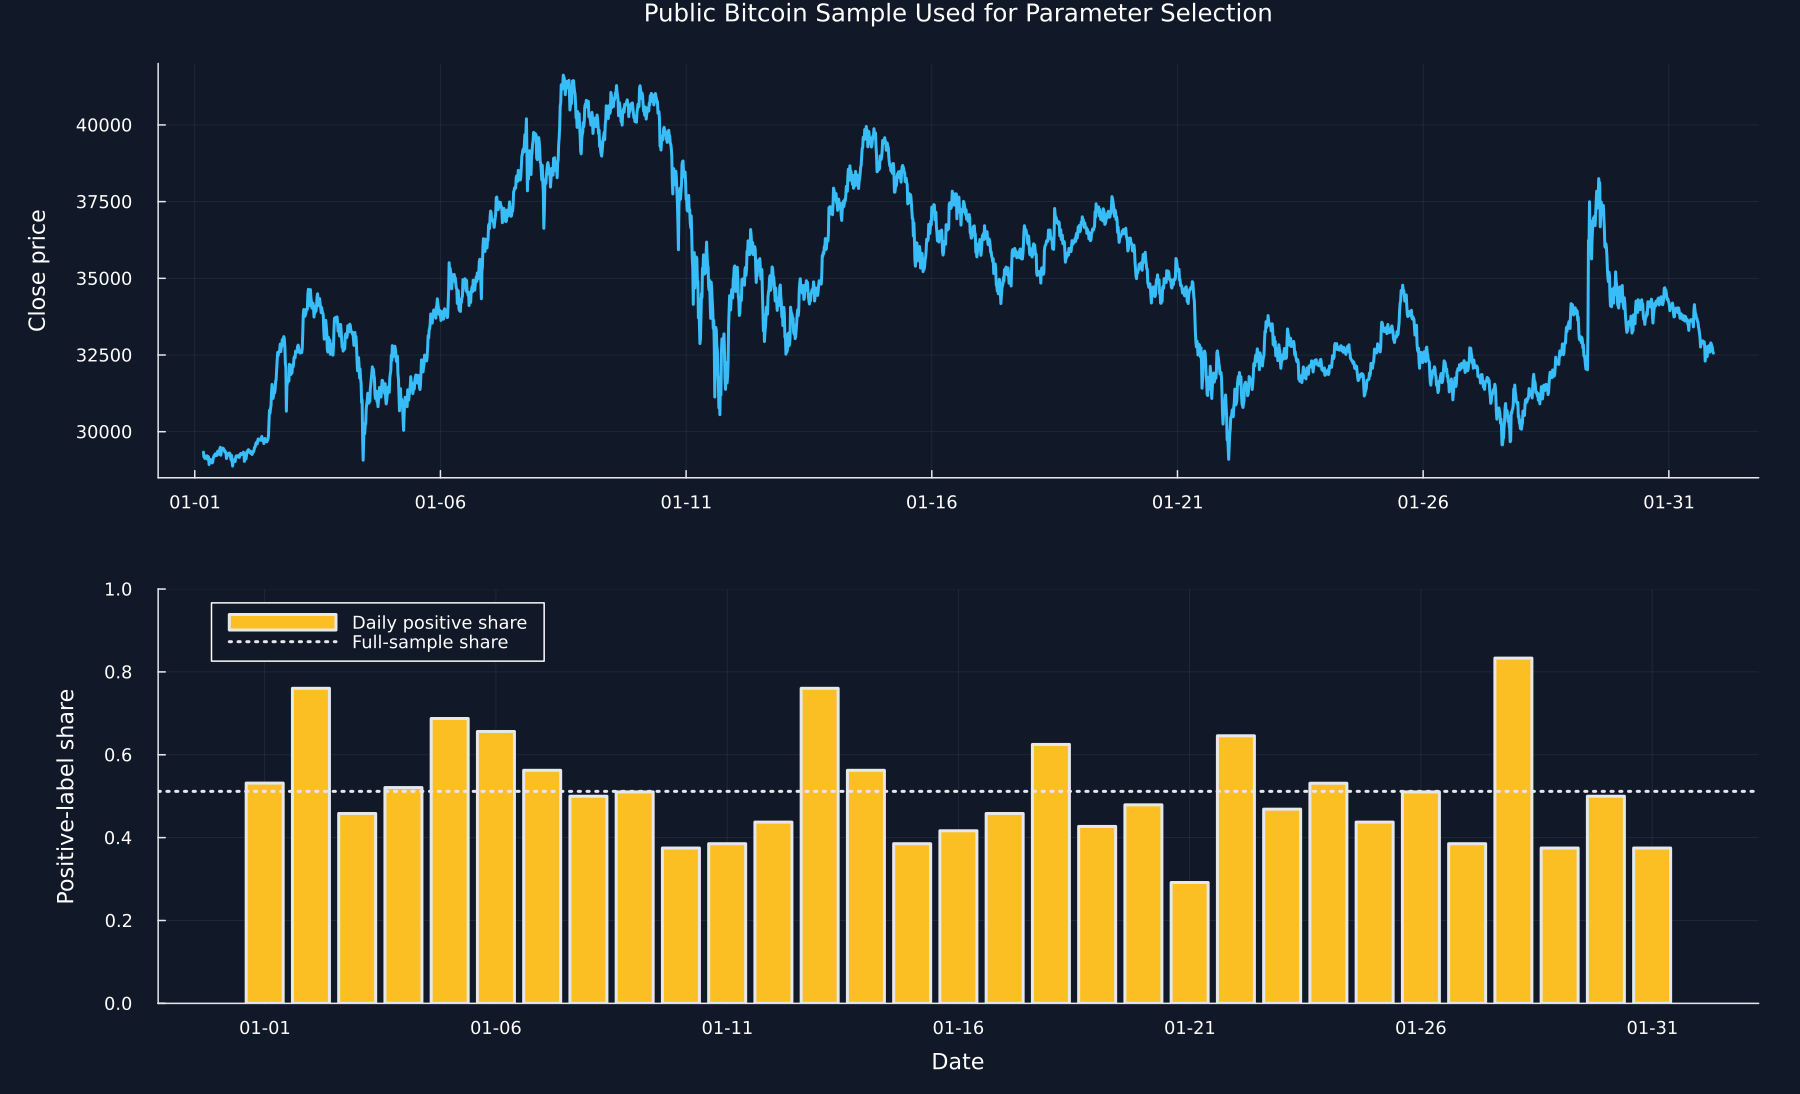

In [2]:
data_provenance = DataFrame("Field"=>["Archive","Provider","Market","Bar length","Label horizon","Analysis start","Analysis end","Observations"],"Value"=>["BTCUSDT-1m-2021-01.zip","Binance Data Vision","Bitcoin to Tether spot market","15 minutes","2 hours",format_time(first(dates)),format_time(last(dates)),"2,951"])
label_balance = DataFrame("Label"=>["Non-positive two-hour return","Positive two-hour return"],"Observations"=>[count(==(0),public_y),count(==(1),public_y)],"Share"=>[mean(public_y.==0),mean(public_y.==1)])
table(data_provenance,"data_provenance","Fixed public observations used for parameter selection.")
table(label_balance,"label_balance","Two-hour direction labels in the public sample.")
daily_direction = combine(groupby(DataFrame(day=Date.(dates),direction=public_y),:day;sort=true),:direction=>mean=>:share)
save_data(daily_direction,paths,"daily_direction")
ticks = collect(Date(2021,1,1):Day(5):Date(2021,1,31))
tick_spec = (Dates.value.(DateTime.(ticks)),Dates.format.(ticks,dateformat"mm-dd"))
p1 = plot(Dates.value.(dates),bars.Close[positions];color=palette.cyan,label="",ylabel="Close price",title="Public Bitcoin Sample Used for Parameter Selection",xticks=tick_spec)
p2 = bar(Dates.value.(DateTime.(daily_direction.day)),daily_direction.share;color=palette.amber,bar_width=Dates.value(Millisecond(Day(1)))*.8,label="Daily positive share",ylabel="Positive-label share",xlabel="Date",ylims=(0,1),xticks=tick_spec,legend=:topleft)
hline!(p2,[mean(public_y)];color=palette.text,linestyle=:dot,label="Full-sample share")
save_figure(plot(p1,p2;layout=(2,1),size=(1200,730),left_margin=8Plots.mm),paths,"public_selection_sample")


## Choosing Inside Each Outer Split

Each outer training set chooses the setting with the largest inner score:

$$
\widehat\theta_m=\arg\max_{\theta\in\Theta}\overline s_m(\theta).
$$

Here, $\Theta$ is the finite set of candidate settings, $\widehat\theta_m$ is the setting selected inside outer split $m$, and $\overline s_m(\theta)$ is the inner score defined above. The outer test observations do not enter this choice.

In [3]:
configuration_grid = configurations([.01,.1,1.,10.])
configuration_catalog = DataFrame("Configuration"=>collect(1:8),"Kernel"=>first.(configuration_grid),"C"=>last.(configuration_grid),"Name"=>[configuration_name(kernel,penalty) for (kernel,penalty) in configuration_grid])
table(configuration_catalog,"configuration_catalog","Candidate settings in the nested public-data search.")
outer_splits = cv_split(PurgedKFoldCV(5,dates,event_times;embargo=.01))
nested_records,inner_surfaces = NamedTuple[],DataFrame[]
for (fold,(train,test)) in enumerate(outer_splits)
    inner_surface,_ = configuration_surface(configuration_grid;rows=train,folds=4,key="nested_inner_"*string(fold))
    chosen = selected_row(inner_surface)
    outer_score = evaluate(chosen.Kernel,chosen.C,train,test,"nested_outer_"*string(fold))
    push!(nested_records,(fold=fold,begins=format_time(dates[first(test)]),ends=format_time(dates[last(test)]),training=length(train),test=length(test),kernel=chosen.Kernel,C=chosen.C,inner=chosen["Mean F1"],outer=outer_score,gap=chosen["Mean F1"]-outer_score))
    current = select(inner_surface,["Configuration","Kernel","C","Mean F1","F1 spread"])
    insertcols!(current,1,"Outer fold"=>fill(fold,nrow(current)))
    push!(inner_surfaces,current)
end
nested_fold_results = DataFrame(nested_records)
rename!(nested_fold_results,["Outer fold","Outer test begins","Outer test ends","Training observations","Test observations","Selected kernel","Selected C","Inner F1","Outer F1","Selection gap"])
nested_inner_surface = vcat(inner_surfaces...)
table(nested_fold_results,"nested_fold_results","Inner choices and untouched outer scores across five protected outer folds.")
table(nested_inner_surface,"nested_inner_surface","Complete inner score surface across the five outer folds.")
save_predictions()


Row,Configuration,Kernel,C,Name
,Int64,String,Float64,String
1,1,linear,0.01,"LINEAR, C=0.01"
2,2,linear,0.1,"LINEAR, C=0.1"
3,3,linear,1.0,"LINEAR, C=1"
4,4,linear,10.0,"LINEAR, C=10"
5,5,rbf,0.01,"RBF, C=0.01"
6,6,rbf,0.1,"RBF, C=0.1"
7,7,rbf,1.0,"RBF, C=1"
8,8,rbf,10.0,"RBF, C=10"


Row,Outer fold,Outer test begins,Outer test ends,Training observations,Test observations,Selected kernel,Selected C,Inner F1,Outer F1,Selection gap
,Int64,String,String,Int64,Int64,String,Float64,Float64,Float64,Float64
1,1,2021-01-01 04:15:00,2021-01-07 07:45:00,2323,591,rbf,10.0,0.373317,0.524752,-0.151435
2,2,2021-01-07 08:00:00,2021-01-13 11:15:00,2316,590,linear,0.1,0.549229,0.536585,0.0126437
3,3,2021-01-13 11:30:00,2021-01-19 14:45:00,2316,590,linear,0.01,0.496925,0.135593,0.361331
4,4,2021-01-19 15:00:00,2021-01-25 18:15:00,2316,590,rbf,1.0,0.549122,0.552352,-0.00322956
5,5,2021-01-25 18:30:00,2021-01-31 21:45:00,2353,590,rbf,10.0,0.527435,0.525773,0.00166135


Row,Outer fold,Configuration,Kernel,C,Mean F1,F1 spread
,Int64,String,String,Float64,Float64,Float64
1,1,"LINEAR, C=0.01",linear,0.01,0.128129,0.174257
2,1,"LINEAR, C=0.1",linear,0.1,0.152524,0.177316
3,1,"LINEAR, C=1",linear,1.0,0.151872,0.173546
4,1,"LINEAR, C=10",linear,10.0,0.151872,0.173546
5,1,"RBF, C=0.01",rbf,0.01,0.0,0.0
6,1,"RBF, C=0.1",rbf,0.1,0.153599,0.0737075
7,1,"RBF, C=1",rbf,1.0,0.325146,0.115545
8,1,"RBF, C=10",rbf,10.0,0.373317,0.041816
9,2,"LINEAR, C=0.01",linear,0.01,0.537596,0.235012


The nested score and the average selection gap are given by:

$$
\widehat S_{\mathrm{nested}}=\frac{1}{K_{\mathrm{out}}}\sum_{m=1}^{K_{\mathrm{out}}} s_m^{\mathrm{out}}(\widehat\theta_m),
\qquad
\widehat O=\frac{1}{K_{\mathrm{out}}}\sum_{m=1}^{K_{\mathrm{out}}}\left[\overline s_m(\widehat\theta_m)-s_m^{\mathrm{out}}(\widehat\theta_m)\right].
$$

Here, $K_{\mathrm{out}}$ is the number of outer folds, $s_m^{\mathrm{out}}(\widehat\theta_m)$ is the score on untouched outer fold $m$, $\widehat S_{\mathrm{nested}}$ is their mean, and $\widehat O$ is the average difference between the selected inner score and its outer score.

Row,Quantity,Value
,String,Float64
1,Candidate settings,8.0
2,Outer folds,5.0
3,Inner folds,4.0
4,Best full-sample inner F1,0.526116
5,Mean selected inner F1,0.499206
6,Mean untouched outer F1,0.455011
7,Mean selection gap,0.0441943
8,Smallest outer F1,0.135593
9,Largest outer F1,0.552352


Row,Selected kernel,Selected C,Outer-fold selections,Selection share
,String,Float64,Int64,Float64
1,linear,0.01,1,0.2
2,linear,0.1,1,0.2
3,rbf,1.0,1,0.2
4,rbf,10.0,2,0.4


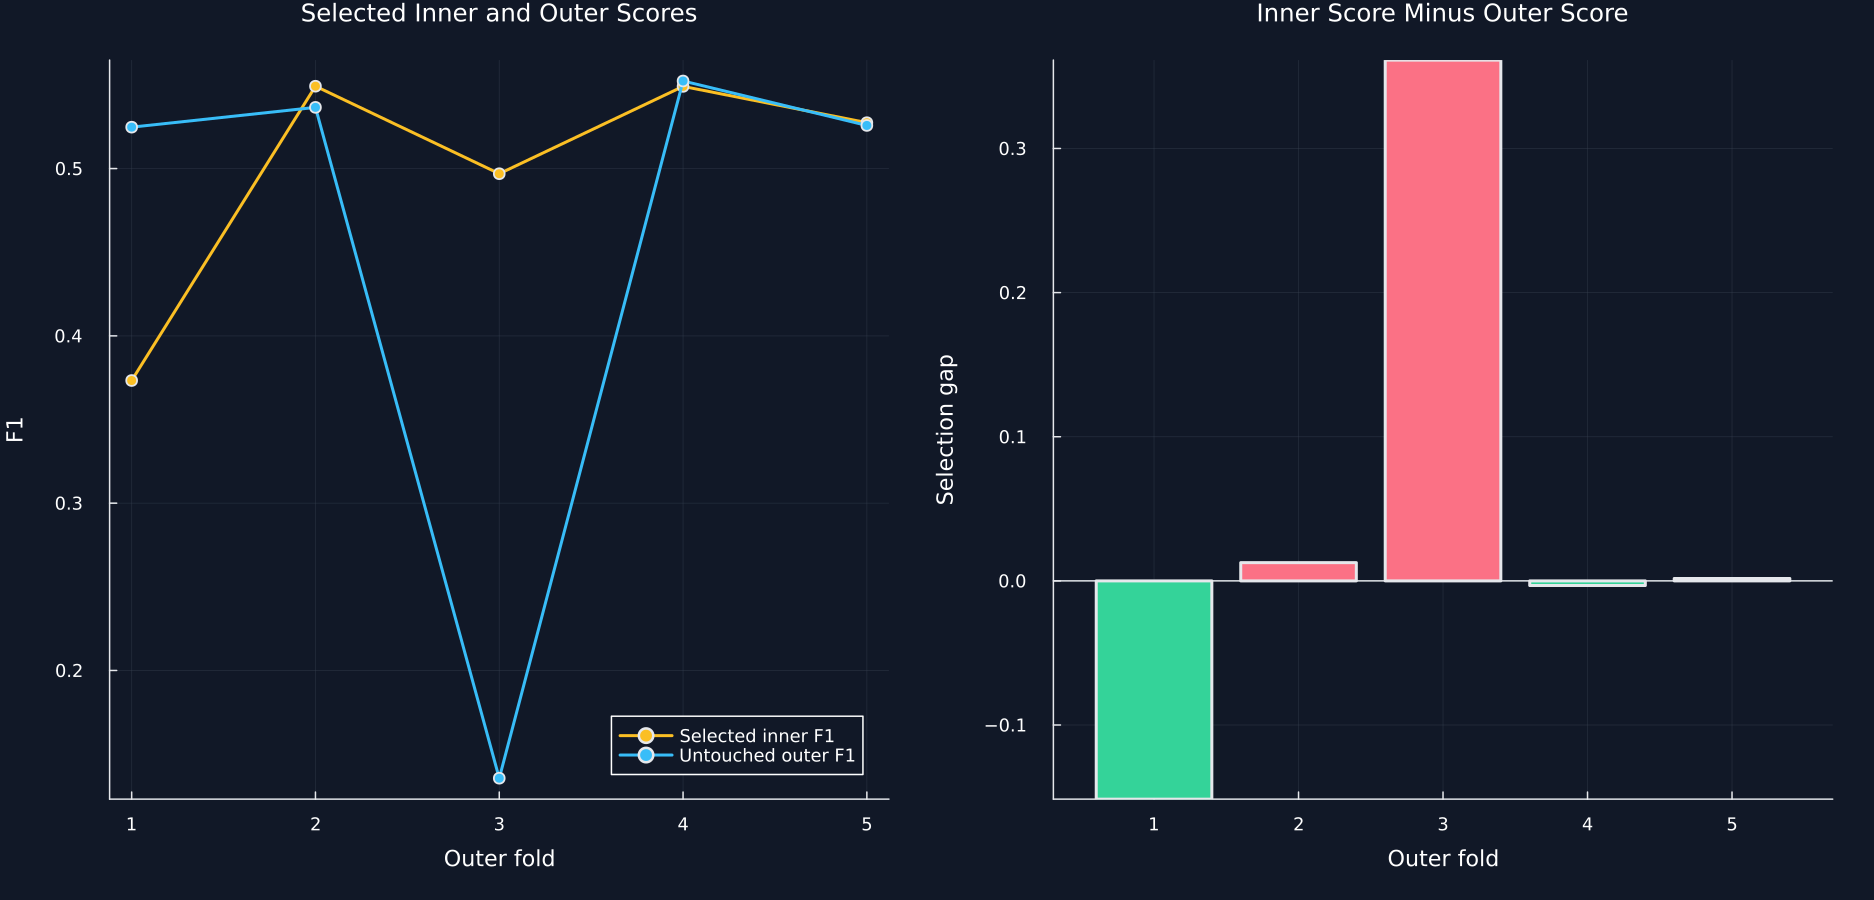

In [4]:
full_surface,_ = configuration_surface(configuration_grid;key="nested_full")
apparent_best = selected_row(full_surface)
nested_summary = DataFrame("Quantity"=>["Candidate settings","Outer folds","Inner folds","Best full-sample inner F1","Mean selected inner F1","Mean untouched outer F1","Mean selection gap","Smallest outer F1","Largest outer F1"],"Value"=>[8,5,4,apparent_best["Mean F1"],mean(nested_fold_results[!,"Inner F1"]),mean(nested_fold_results[!,"Outer F1"]),mean(nested_fold_results[!,"Selection gap"]),minimum(nested_fold_results[!,"Outer F1"]),maximum(nested_fold_results[!,"Outer F1"])])
selection_frequency_table = selection_frequency(nested_fold_results,"Outer-fold selections")
table(nested_summary,"nested_summary","Nested-selection summary for the public experiment.")
table(selection_frequency_table,"nested_selection_frequency","Frequency of selected settings across protected outer folds.")
p1 = plot(1:5,nested_fold_results[!,"Inner F1"];marker=:circle,color=palette.amber,label="Selected inner F1",title="Selected Inner and Outer Scores",xlabel="Outer fold",ylabel="F1",xticks=1:5,legend=:bottomright)
plot!(p1,1:5,nested_fold_results[!,"Outer F1"];marker=:circle,color=palette.cyan,label="Untouched outer F1")
gaps = nested_fold_results[!,"Selection gap"]
p2 = bar(1:5,gaps;color=ifelse.(gaps.>=0,palette.rose,palette.green),label="",title="Inner Score Minus Outer Score",xlabel="Outer fold",ylabel="Selection gap",xticks=1:5)
hline!(p2,[0.];color=palette.text,label="",linewidth=1)
save_figure(plot(p1,p2;layout=(1,2),size=(1250,600),bottom_margin=8Plots.mm),paths,"nested_inner_outer_scores")


## Tests

In [5]:
@assert count_observations==2951
@assert length(dates)==length(event_times)
@assert Set(public_y)==Set([0,1])
@assert sum(label_balance.Observations)==count_observations
@assert sum(label_balance.Share)≈1
@assert size(configuration_catalog)==(8,4)
@assert length(outer_splits)==5
@assert size(nested_fold_results)==(5,10)
@assert size(nested_inner_surface)==(40,6)
@assert all(value->0<=value<=1,nested_fold_results[!,"Inner F1"])
@assert all(value->0<=value<=1,nested_fold_results[!,"Outer F1"])
@assert all(>(0),nested_fold_results[!,"Training observations"])
@assert sum(nested_fold_results[!,"Test observations"])==count_observations
@assert size(full_surface)==(8,10)
@assert size(nested_summary)==(9,2)
@assert sum(selection_frequency_table[!,"Outer-fold selections"])==5
@assert sum(selection_frequency_table[!,"Selection share"])≈1
for (train,test) in outer_splits
    @assert isempty(intersect(train,test))
    @assert overlap_count(train,test)==0
end
@assert all(row.converged for row in fit_records)
@assert isfile(joinpath(paths.figures,"public_selection_sample.pdf"))
@assert isfile(joinpath(paths.figures,"nested_inner_outer_scores.pdf"))
@assert isfile(joinpath(paths.tables,"data_provenance.tex"))
@assert isfile(joinpath(paths.tables,"label_balance.tex"))
@assert isfile(joinpath(paths.tables,"configuration_catalog.tex"))
@assert isfile(joinpath(paths.tables,"nested_fold_results.tex"))
@assert isfile(joinpath(paths.tables,"nested_inner_surface.tex"))
@assert isfile(joinpath(paths.tables,"nested_summary.tex"))
@assert isfile(joinpath(paths.tables,"nested_selection_frequency.tex"))
